Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving all models & results to: /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison
TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

=== GitHub Repository Connection (Upfront Setup) ===
Enter your GitHub Personal Access Token (PAT): ··········
Enter your GitHub Email: uzairrshahid@gmail.com
Cloning into '/content/Study-Deep-Learning'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 45 (delta 8), reused 40 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (45/45), 3.69 MiB | 3.10 MiB/s, done.
Resolving deltas: 100% (8/8), done.

✅ GitHub repository connected. Local directory at: /content/Study-Deep-Learning


100%|██████████| 267M/267M [00:13<00:00, 20.4MB/s]

Extracting files...


Found 661 files belonging to 2 classes.
Found 453 files belonging to 2 classes.
Found 449 files belonging to 2 classes.
Classes: ['Fake', 'Real']
Train Fake=240 Real=422 | class_weight={0: 1.379, 1: 0.784}

VGG16 (scratch): 14,858,945 params — ALL trainable, randomly initialised, no ImageNet weights
Epoch 1/16
42/42 - 45s - 1s/step - accuracy: 0.7958 - auc: 0.8885 - loss: 0.4649 - val_accuracy: 0.6203 - val_auc: 0.2420 - val_loss: 1.1248 - learning_rate: 1.0000e-04
Epoch 2/16
42/42 - 17s - 413ms/step - accuracy: 0.8578 - auc: 0.9335 - loss: 0.3665 - val_accuracy: 0.6446 - val_auc: 0.8439 - val_loss: 1.1674 - learning_rate: 1.0000e-04
Epoch 3/16
42/42 - 18s - 428ms/step - accuracy: 0.8956 - auc: 0.9589 - loss: 0.2929 - val_accuracy: 0.6667 - val_auc: 0.8620 - val_loss: 0.9243 - learning_rate: 1.0000e-04
Epoch 4/16
42/42 - 19s - 450ms/step - accuracy: 0.8941 - auc: 0.9634 - loss: 0.2765 - val_accuracy: 0.7859 - val_auc: 0.8817 - val_loss: 0.5414 - learning_rate: 1.0000e-04
Epoch 5/16
42/

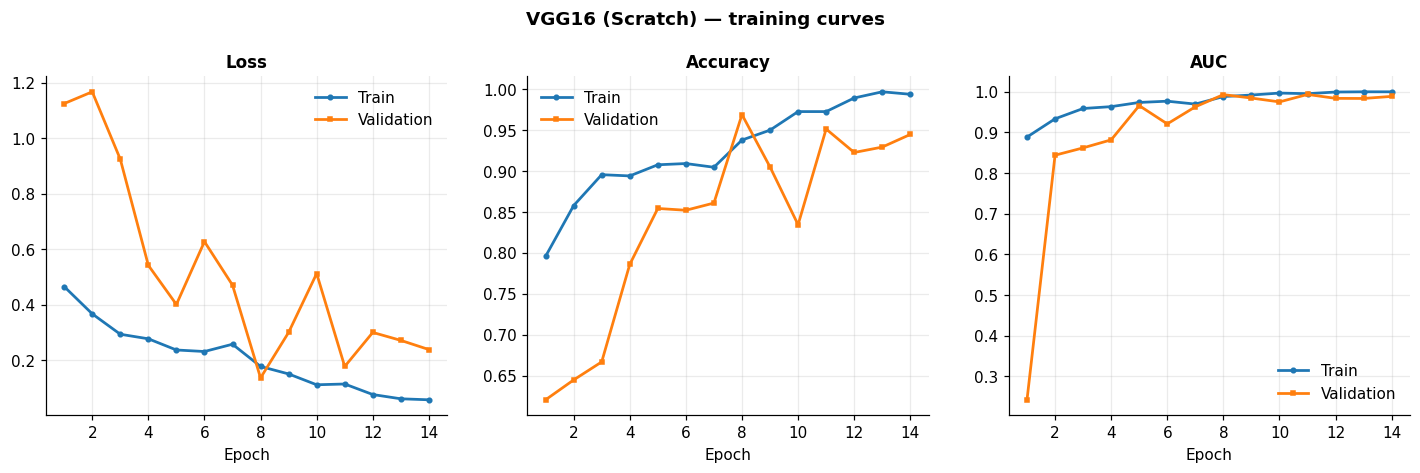

  saved plot -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/plots/vgg16_scratch_training_curves.png


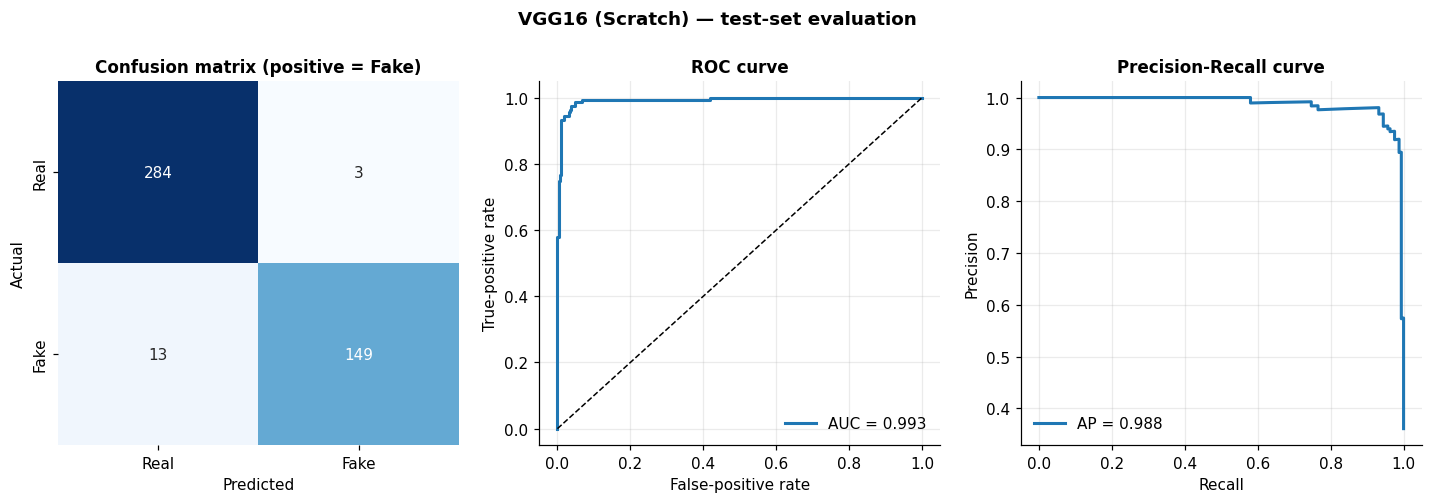

  saved plot -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/plots/vgg16_scratch_evaluation.png
              precision    recall  f1-score   support

        Real     0.9562    0.9895    0.9726       287
        Fake     0.9803    0.9198    0.9490       162

    accuracy                         0.9644       449
   macro avg     0.9682    0.9547    0.9608       449
weighted avg     0.9649    0.9644    0.9641       449

  saved model   -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/models/vgg16_scratch.keras
  saved results -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/results/vgg16_scratch_[history.csv | meta.json | preds.npz]

✅ Cell 1 done — now run Cell 2 (ImageNet transfer learning).


In [5]:
!pip install -q kagglehub scikit-learn seaborn

import os, json, time, warnings, shutil
from getpass import getpass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub
from tensorflow.keras import layers, models, regularizers, callbacks
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score, precision_score,
                             recall_score, f1_score, accuracy_score, matthews_corrcoef,
                             balanced_accuracy_score)
warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- config
SEED          = 42
IMG_SIZE      = (224, 224)
BATCH_SIZE    = 16
MAX_EPOCHS_SCRATCH = 16        # <-- hard cap for the from-scratch model
USE_BATCHNORM = True           # True  = VGG16 + BatchNorm (trains reliably from random init on small data)
                               # False = exact original Keras VGG16 (weights=None); often stalls without BN
SCRATCH_TAG, SCRATCH_NAME = "vgg16_scratch",  "VGG16 (Scratch)"
TL_TAG,      TL_NAME      = "vgg16_transfer", "VGG16 (ImageNet Transfer)"
COLORS = {SCRATCH_NAME: "#E69F00", TL_NAME: "#0072B2"}     # colour-blind-safe pair (Okabe-Ito)

tf.random.set_seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "legend.frameon": False})

# ------------------------------------------------- 1. Connect Google Drive
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison"
except Exception as e:
    print("Drive mount status:", e)
    BASE_DIR = os.path.abspath("VGG16_Comparison")          # fallback when not on Colab

MODEL_DIR, RES_DIR, PLOT_DIR = [os.path.join(BASE_DIR, d) for d in ("models", "results", "plots")]
for d in (MODEL_DIR, RES_DIR, PLOT_DIR):
    os.makedirs(d, exist_ok=True)
print("Saving all models & results to:", BASE_DIR)
print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

# ------------------------------------------------- 2. Connect GitHub upfront
print("\n=== GitHub Repository Connection (Upfront Setup) ===")
github_token = getpass("Enter your GitHub Personal Access Token (PAT): ")
github_email = input("Enter your GitHub Email: ")
github_username = "uzairshahidgithub"
repo_url = "github.com/uzairshahidgithub/Study-Deep-Learning.git"

# Configure Git
!git config --global user.email "{github_email}"
!git config --global user.name "{github_username}"

# Clone the repository securely using the PAT
repo_path = "/content/Study-Deep-Learning"
if os.path.exists(repo_path):
    shutil.rmtree(repo_path)

!git clone https://{github_token}@{repo_url} {repo_path}
github_token = None  # Clear token immediately from variable memory for security
print("\n✅ GitHub repository connected. Local directory at:", repo_path)

# ---------------------------------------------------------------- dataset
dataset_path = kagglehub.dataset_download("surajkumarjha1/fake-vs-real-medicine-datasets-images")
split_dirs = None
for root, dirs, _ in os.walk(dataset_path):
    low = {d.lower(): d for d in dirs}
    if {"train", "val", "test"}.issubset(low):
        split_dirs = {k: os.path.join(root, low[k]) for k in ("train", "val", "test")}
        break
if split_dirs is None:
    raise FileNotFoundError("Could not find train / val / test folders in the dataset.")
train_dir, val_dir, test_dir = split_dirs["train"], split_dirs["val"], split_dirs["test"]

def load_split(path, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        path, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="binary",
        shuffle=shuffle, seed=SEED)

train_raw, val_raw, test_raw = load_split(train_dir, True), load_split(val_dir, False), load_split(test_dir, False)
CLASS_NAMES = train_raw.class_names                    # alphabetical -> ['Fake', 'Real']  (Fake=0, Real=1)
TEST_FILES  = list(test_raw.file_paths)                # kept for qualitative gallery
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_raw.cache().prefetch(AUTOTUNE)
val_ds   = val_raw.cache().prefetch(AUTOTUNE)
test_ds  = test_raw.cache().prefetch(AUTOTUNE)
print("Classes:", CLASS_NAMES)

def count_class(dir_, cls):
    return len(os.listdir(os.path.join(dir_, cls)))
n_fake, n_real = count_class(train_dir, CLASS_NAMES[0]), count_class(train_dir, CLASS_NAMES[1])
total = n_fake + n_real
class_weight = {0: total / (2.0 * n_fake), 1: total / (2.0 * n_real)}
print(f"Train Fake={n_fake} Real={n_real} | class_weight={ {k: round(v, 3) for k, v in class_weight.items()} }")

# ---------------------------------------------------------------- shared helpers
class TimeHistory(callbacks.Callback):
    def __init__(self): super().__init__(); self.times = []
    def on_epoch_begin(self, epoch, logs=None): self._t = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self._t)

def make_augmentation():
    return tf.keras.Sequential([
        layers.RandomRotation(0.05), layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05), layers.RandomContrast(0.1)], name="augmentation")

def build_head(x):
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dense(256, activation="relu", kernel_regularizer=regularizers.l2(1e-4), name="fc1")(x)
    x = layers.Dropout(0.5, name="drop")(x)
    return layers.Dense(1, activation="sigmoid", name="pred")(x)

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])

def evaluate_model(model, name):
    test_loss = float(model.evaluate(test_ds, verbose=0)[0])
    prob_real = model.predict(test_ds, verbose=0).ravel()
    y_true = np.concatenate([y.numpy().ravel() for _, y in test_ds]).astype(int)
    y_fake, s_fake = 1 - y_true, 1 - prob_real
    pred_fake = (s_fake >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_fake, pred_fake, labels=[0, 1]).ravel()
    m = dict(model=name, test_loss=test_loss, accuracy=accuracy_score(y_fake, pred_fake),
             balanced_accuracy=balanced_accuracy_score(y_fake, pred_fake),
             precision=precision_score(y_fake, pred_fake, zero_division=0),
             recall=recall_score(y_fake, pred_fake, zero_division=0),
             specificity=tn / (tn + fp) if (tn + fp) else 0.0,
             f1=f1_score(y_fake, pred_fake, zero_division=0),
             mcc=matthews_corrcoef(y_fake, pred_fake),
             roc_auc=roc_auc_score(y_fake, s_fake), pr_auc=average_precision_score(y_fake, s_fake),
             tp=int(tp), fp=int(fp), tn=int(tn), fn=int(fn))
    return m, y_true, prob_real

def save_fig(fig, name):
    path = os.path.join(PLOT_DIR, name + ".png")
    fig.savefig(path, dpi=160, bbox_inches="tight"); plt.show()
    print("  saved plot ->", path)

def plot_training(hist, title, tag, boundary=None):
    ep = np.arange(1, len(hist["loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for a, (k, lab) in zip(ax, [("loss", "Loss"), ("accuracy", "Accuracy"), ("auc", "AUC")]):
        a.plot(ep, hist[k], "-o", ms=3, lw=1.8, label="Train")
        a.plot(ep, hist["val_" + k], "-s", ms=3, lw=1.8, label="Validation")
        if boundary: a.axvline(boundary + 0.5, color="gray", ls=":", lw=1.2)
        a.set_title(f"{lab}"); a.set_xlabel("Epoch"); a.legend()
    if boundary:
        ax[0].text(boundary + 0.6, ax[0].get_ylim()[1] * 0.97, "fine-tune ->", fontsize=8, va="top", color="gray")
    fig.suptitle(title, fontweight="bold", y=1.03)
    save_fig(fig, tag + "_training_curves")

def plot_eval(m, y_true, prob_real, title, tag):
    y_fake, s_fake = 1 - y_true, 1 - prob_real
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
                xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
    ax[0].set_title("Confusion matrix (positive = Fake)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")
    ax[0].grid(False)
    fpr, tpr, _ = roc_curve(y_fake, s_fake)
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {m['roc_auc']:.3f}"); ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set_title("ROC curve"); ax[1].set_xlabel("False-positive rate"); ax[1].set_ylabel("True-positive rate"); ax[1].legend()
    p, r, _ = precision_recall_curve(y_fake, s_fake)
    ax[2].plot(r, p, lw=2, label=f"AP = {m['pr_auc']:.3f}")
    ax[2].set_title("Precision-Recall curve"); ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].legend()
    fig.suptitle(title, fontweight="bold", y=1.03)
    save_fig(fig, tag + "_evaluation")
    print(classification_report(y_fake, (s_fake >= .5).astype(int), target_names=["Real", "Fake"], digits=4))

def save_result(tag, name, model, hist, metrics, y_true, prob_real, train_time, epoch_times, extra=None):
    model.save(os.path.join(MODEL_DIR, tag + ".keras"))
    pd.DataFrame(hist).assign(epoch=lambda d: np.arange(1, len(d) + 1),
                              epoch_time_s=epoch_times).to_csv(os.path.join(RES_DIR, tag + "_history.csv"), index=False)
    np.savez(os.path.join(RES_DIR, tag + "_preds.npz"), y_true=y_true, prob_real=prob_real,
             files=np.array(TEST_FILES))
    best_ep = int(np.argmin(hist["val_loss"])) + 1
    meta = dict(name=name, tag=tag, metrics=metrics, train_time_s=train_time, epochs_run=len(hist["loss"]),
                best_epoch=best_ep, total_params=int(model.count_params()),
                trainable_params=int(sum(np.prod(w.shape) for w in model.trainable_weights)),
                class_names=CLASS_NAMES, **(extra or {}))
    json.dump(meta, open(os.path.join(RES_DIR, tag + "_meta.json"), "w"), indent=2)
    print(f"  saved model   -> {os.path.join(MODEL_DIR, tag + '.keras')}")
    print(f"  saved results -> {RES_DIR}/{tag}_[history.csv | meta.json | preds.npz]")
    return meta

# ================================================================ MODEL 1: VGG16 FROM SCRATCH
def build_vgg16_scratch(use_bn=USE_BATCHNORM):
    if use_bn:
        inp = layers.Input(shape=IMG_SIZE + (3,))
        x = inp
        for b, (f, n) in enumerate([(64, 2), (128, 2), (256, 3), (512, 3), (512, 3)], 1):
            for i in range(1, n + 1):
                x = layers.Conv2D(f, 3, padding="same", use_bias=False, kernel_initializer="he_normal",
                                  name=f"block{b}_conv{i}")(x)
                x = layers.BatchNormalization(name=f"block{b}_bn{i}")(x)
                x = layers.Activation("relu", name=f"block{b}_relu{i}")(x)
            x = layers.MaxPooling2D(2, name=f"block{b}_pool")(x)
        base = models.Model(inp, x, name="vgg16_bn_scratch_base")
    else:
        base = tf.keras.applications.VGG16(weights=None, include_top=False, input_shape=IMG_SIZE + (3,))
    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = make_augmentation()(inputs)
    x = layers.Rescaling(1.0 / 255)(x)
    x = base(x)
    return models.Model(inputs, build_head(x), name="VGG16_from_scratch")

scratch_model = build_vgg16_scratch()
compile_model(scratch_model, 1e-4)
print(f"\nVGG16 (scratch): {scratch_model.count_params():,} params — ALL trainable, randomly initialised, no ImageNet weights")

# ---------------------------------------------------------------- train (max 16 epochs)
t_scratch = TimeHistory()
cbs = [t_scratch,
       callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
       callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)]
t0 = time.time()
h = scratch_model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS_SCRATCH,
                      class_weight=class_weight, callbacks=cbs, verbose=2)
train_time_scratch = time.time() - t0
hist_scratch = {k: [float(v) for v in vals] for k, vals in h.history.items() if k != "learning_rate"}
assert len(hist_scratch["loss"]) <= 16, "scratch model exceeded 16 epochs"
print(f"\nScratch training finished: {len(hist_scratch['loss'])} epochs in {train_time_scratch/60:.1f} min")

# ---------------------------------------------------------------- evaluate, plot, save
m_scratch, y_true_s, prob_s = evaluate_model(scratch_model, SCRATCH_NAME)
print("\nTEST RESULTS —", SCRATCH_NAME)
print(pd.Series({k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_scratch.items()}).to_string())
plot_training(hist_scratch, f"{SCRATCH_NAME} — training curves", SCRATCH_TAG)
plot_eval(m_scratch, y_true_s, prob_s, f"{SCRATCH_NAME} — test-set evaluation", SCRATCH_TAG)
meta_scratch = save_result(SCRATCH_TAG, SCRATCH_NAME, scratch_model, hist_scratch, m_scratch, y_true_s, prob_s,
                           train_time_scratch, t_scratch.times, extra=dict(use_batchnorm=USE_BATCHNORM))
print("\n✅ Cell 1 done — now run Cell 2 (ImageNet transfer learning).")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
VGG16 (ImageNet): 14,846,273 params | Phase-1 trainable (head only): 131,585
Epoch 1/8
42/42 - 4s - 87ms/step - accuracy: 0.8336 - auc: 0.9073 - loss: 0.7002 - val_accuracy: 0.9448 - val_auc: 0.9823 - val_loss: 0.2215
Epoch 2/8
42/42 - 1s - 14ms/step - accuracy: 0.9349 - auc: 0.9775 - loss: 0.2340 - val_accuracy: 0.9713 - val_auc: 0.9933 - val_loss: 0.1160
Epoch 3/8
42/42 - 1s - 14ms/step - accuracy: 0.9531 - auc: 0.9865 - loss: 0.1997 - val_accuracy: 0.9713 - val_auc: 0.9939 - val_loss: 0.1182
Epoch 4/8
42/42 - 1s - 14ms/step - accuracy: 0.9531 - auc: 0.9884 - loss: 0.1709 - val_accuracy: 0.9735 - val_auc: 0.9983 - val_loss: 0.0822
Epoch 5/8
42/42 - 1s - 14ms/step - accuracy: 0.9576 - auc: 0.9915 - loss: 0.1507 - val_accuracy: 0.9801 - val_auc: 0.9988 - val_loss: 0.0821
Epoch 6/8
42/42 - 1s - 14ms/step - accuracy: 0.9622 - auc: 0.9943 - loss: 0.1219 - val_accuracy: 0.9868 - val_auc: 0.9998 - val_loss: 0.0747
Epoch 7/8
42/42 - 1s - 14m

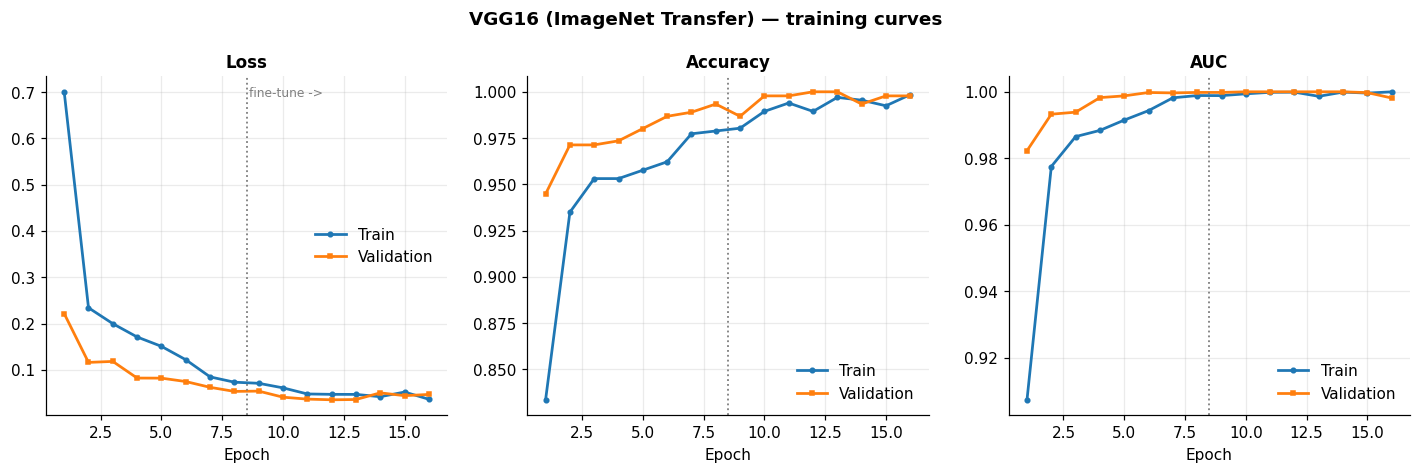

  saved plot -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/plots/vgg16_transfer_training_curves.png


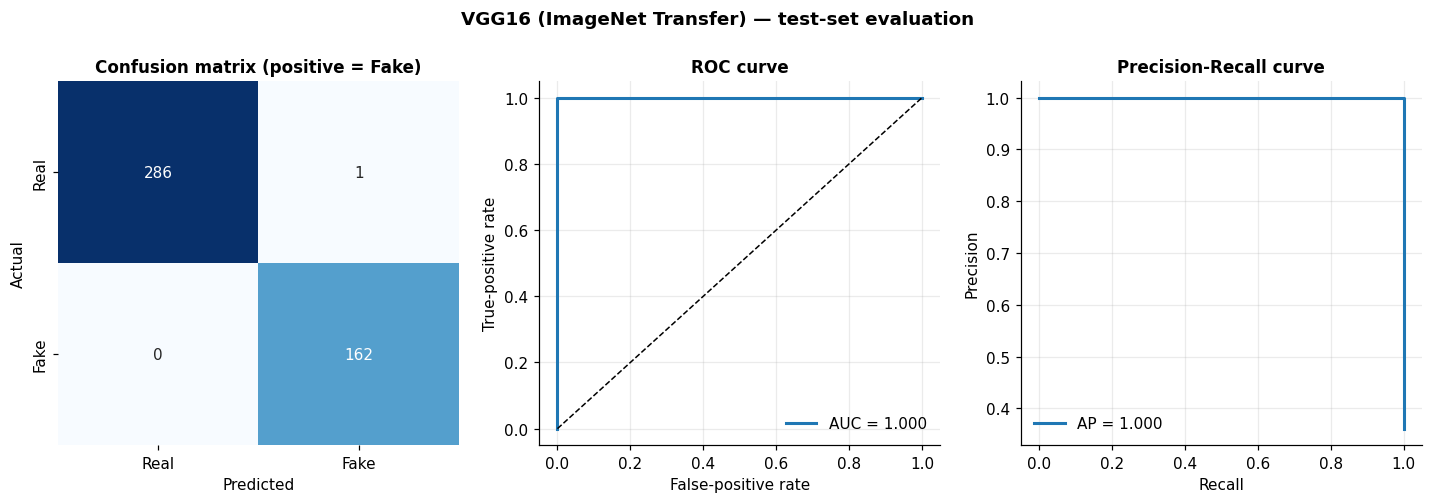

  saved plot -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/plots/vgg16_transfer_evaluation.png
              precision    recall  f1-score   support

        Real     1.0000    0.9965    0.9983       287
        Fake     0.9939    1.0000    0.9969       162

    accuracy                         0.9978       449
   macro avg     0.9969    0.9983    0.9976       449
weighted avg     0.9978    0.9978    0.9978       449

  saved model   -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/models/vgg16_transfer.keras
  saved results -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/results/vgg16_transfer_[history.csv | meta.json | preds.npz]

✅ Cell 2 done — now run Cell 3 (comparison).


In [ ]:
# =====================================================================
# CELL 2 — VGG16 TRANSFER LEARNING  (pre-trained ImageNet weights)
# NOT the Cell-1 model: this is a fresh, already-trained VGG16 from Keras.
#   Phase 1: freeze the ImageNet conv base, train only the new head
#   Phase 2: unfreeze block5 and fine-tune with a very small learning rate
# Same data, augmentation, head, class weights and 16-epoch budget as Cell 1.
# =====================================================================
assert "train_ds" in globals(), "Run Cell 1 first (it loads the data and shared helpers)."

PHASE1_EPOCHS, PHASE2_EPOCHS = 8, 8          # 8 + 8 = 16 epochs total (same budget as scratch)

@tf.keras.utils.register_keras_serializable(package="medicine")
class VGGPreprocess(layers.Layer):
    """Keras VGG16 / ImageNet preprocessing (RGB->BGR, subtract ImageNet channel means), saveable in .keras."""
    def call(self, x):
        x = tf.cast(x, tf.float32)[..., ::-1]
        return x - tf.constant([103.939, 116.779, 123.68], dtype=tf.float32)
    def compute_output_shape(self, s): return s

def build_vgg16_transfer():
    base = tf.keras.applications.VGG16(weights="imagenet", include_top=False,
                                       input_shape=IMG_SIZE + (3,))        # <- pre-trained ImageNet weights
    base.trainable = False                                                  # Phase 1: frozen
    inputs = layers.Input(shape=IMG_SIZE + (3,))
    x = make_augmentation()(inputs)
    x = VGGPreprocess(name="vgg_preprocess")(x)
    x = base(x, training=False)
    return models.Model(inputs, build_head(x), name="VGG16_transfer"), base

tl_model, vgg_base = build_vgg16_transfer()
n_total, n_train = tl_model.count_params(), int(sum(np.prod(w.shape) for w in tl_model.trainable_weights))
print(f"VGG16 (ImageNet): {n_total:,} params | Phase-1 trainable (head only): {n_train:,}")

t_tl = TimeHistory()
t0 = time.time()

# ------------------------------------------------- Phase 1: train the head, base frozen
compile_model(tl_model, 1e-3)
h1 = tl_model.fit(train_ds, validation_data=val_ds, epochs=PHASE1_EPOCHS, class_weight=class_weight, verbose=2,
                  callbacks=[t_tl, callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                                           restore_best_weights=True, verbose=1)])

# ------------------------------------------------- Phase 2: fine-tune block5 with a tiny LR
vgg_base.trainable = True
for layer in vgg_base.layers:
    layer.trainable = layer.name.startswith("block5")
compile_model(tl_model, 1e-5)                                  # must re-compile after changing trainable
n_train2 = int(sum(np.prod(w.shape) for w in tl_model.trainable_weights))
print(f"\nPhase 2: fine-tuning block5 -> trainable params: {n_train2:,}")
h2 = tl_model.fit(train_ds, validation_data=val_ds, epochs=PHASE2_EPOCHS, class_weight=class_weight, verbose=2,
                  callbacks=[t_tl, callbacks.EarlyStopping(monitor="val_loss", patience=4,
                                                           restore_best_weights=True, verbose=1)])
train_time_tl = time.time() - t0

keys = ["loss", "accuracy", "auc", "val_loss", "val_accuracy", "val_auc"]
hist_tl = {k: [float(v) for v in h1.history[k] + h2.history[k]] for k in keys}
boundary = len(h1.history["loss"])
print(f"\nTransfer learning finished: {len(hist_tl['loss'])} epochs in {train_time_tl/60:.1f} min")

# ------------------------------------------------- evaluate, plot, save
m_tl, y_true_t, prob_t = evaluate_model(tl_model, TL_NAME)
print("\nTEST RESULTS —", TL_NAME)
print(pd.Series({k: (round(v, 4) if isinstance(v, float) else v) for k, v in m_tl.items()}).to_string())
plot_training(hist_tl, f"{TL_NAME} — training curves", TL_TAG, boundary=boundary)
plot_eval(m_tl, y_true_t, prob_t, f"{TL_NAME} — test-set evaluation", TL_TAG)
meta_tl = save_result(TL_TAG, TL_NAME, tl_model, hist_tl, m_tl, y_true_t, prob_t, train_time_tl, t_tl.times,
                      extra=dict(phase1_epochs=boundary, phase2_epochs=len(hist_tl["loss"]) - boundary,
                                 trainable_params_phase1=n_train, trainable_params_phase2=n_train2))
print("\n✅ Cell 2 done — now run Cell 3 (comparison).")


MODEL SUMMARY: VGG16 FROM SCRATCH


Model: "VGG16_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16_bn_scratch_base           │ (None, 7, 7, 512)      │    14,727,360 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pred (Dense)                    │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,559,941 (169.98 MB)

 Trainable params: 14,850,497 (56.65 MB)

...

 Total params: 29,268,293 (111.65 MB)

 Trainable params: 7,211,009 (27.51 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

 Optimizer params: 14,422,020 (55.02 MB)


PERFORMANCE & EFFICIENCY COMPARISON
Model                 VGG16 (Scratch) VGG16 (ImageNet Transfer)
Test accuracy                  0.9555                    0.9978
Balanced acc.                  0.9584                    0.9983
Precision (Fake)               0.9128                    0.9939
Recall (Fake)                  0.9691                    1.0000
Specificity                    0.9477                    0.9965
F1 (Fake)                      0.9401                    0.9969
MCC                            0.9057                    0.9952
ROC-AUC                        0.9883                    1.0000
PR-AUC                         0.9820                    1.0000
Test loss                      0.1526                    0.0379
Missed fakes (FN)              5.0000                    0.0000
False alarms (FP)             15.0000                    1.0000
Epochs run                    16.0000                   16.0000
Best epoch (val loss)         10.0000                   12.0000
Fin

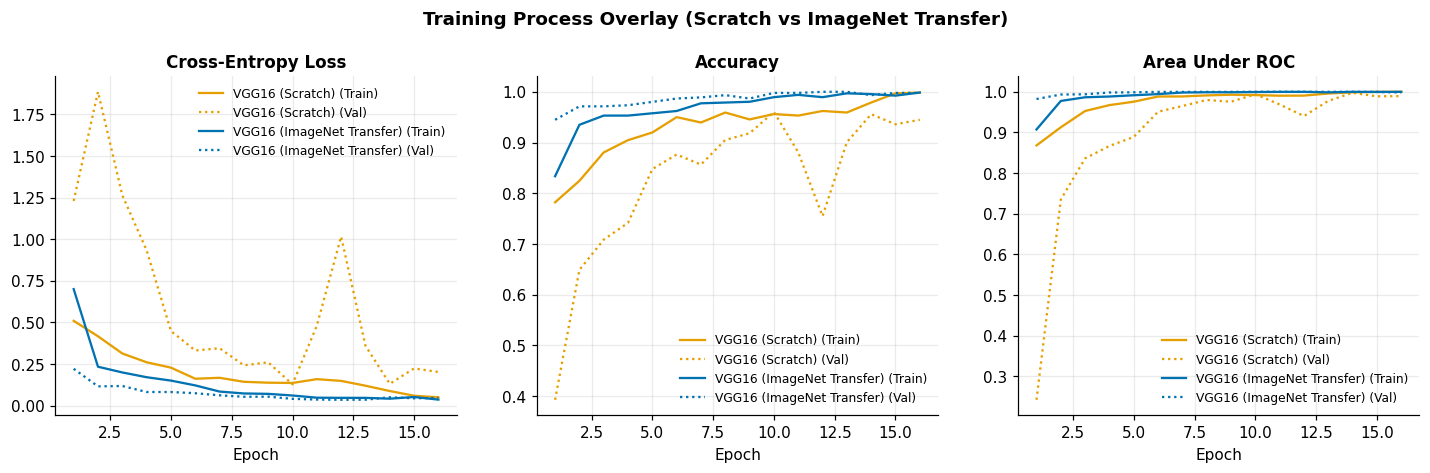

  saved plot -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/plots/comparison_learning_curves.png


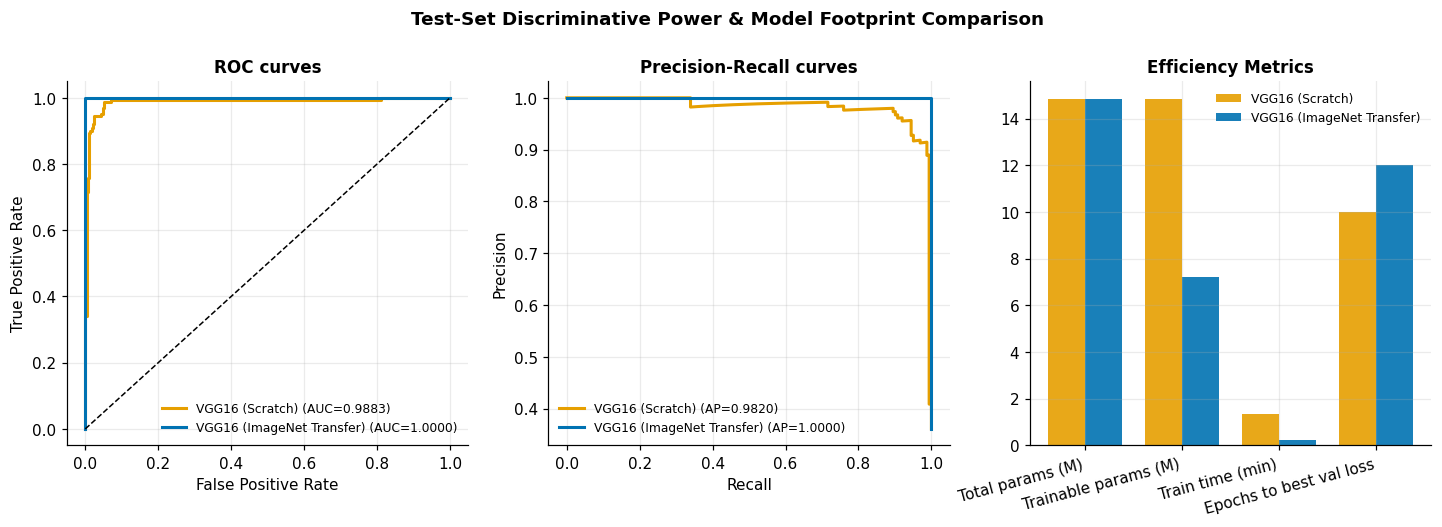

  saved plot -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/plots/comparison_evaluation_curves.png

MC-NEMAR SIGNIFICANCE TEST
Discordant image count: 21 of 449 total
  -> Scratch correct, Transfer incorrect: 1
  -> Scratch incorrect, Transfer correct: 20
Two-sided binomial exact p-value = 2.098e-05
  Result is STATISTICALLY SIGNIFICANT at alpha = 0.05

Generated summary report written to: /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/vgg16_full_comparison_report.txt

QUALITATIVE TEST DISCORDANCES GALLERY


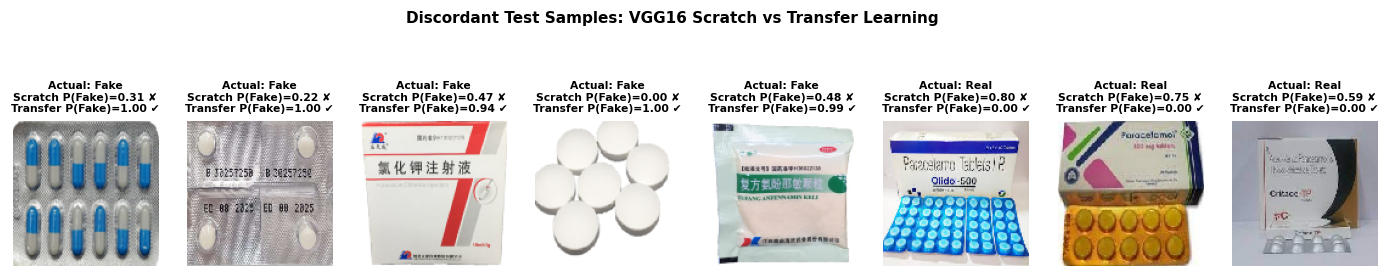

  saved plot -> /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison/plots/comparison_discordant_samples.png

✅ Cell 3 Comparison completed successfully! All plots and reports saved to: /content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison


In [ ]:
# =====================================================================
# CELL 3 — COMPARISON: VGG16 from Scratch  vs  VGG16 ImageNet Transfer Learning
# Reads both models' results (from memory, or from Google Drive if the runtime restarted),
# draws the comparison graphs, runs a statistical test, and saves everything to Drive.
# =====================================================================
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import binomtest
from sklearn.metrics import roc_curve, precision_recall_curve
warnings.filterwarnings("ignore")

# ---- make Cell 3 runnable on its own after a runtime restart --------------------------
if "BASE_DIR" not in globals():
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = "/content/drive/MyDrive/Medicine_Classifier_Project/VGG16_Comparison"
    except Exception:
        BASE_DIR = os.path.abspath("VGG16_Comparison")
    MODEL_DIR, RES_DIR, PLOT_DIR = [os.path.join(BASE_DIR, d) for d in ("models", "results", "plots")]
    for d in (MODEL_DIR, RES_DIR, PLOT_DIR): os.makedirs(d, exist_ok=True)
    SCRATCH_TAG, SCRATCH_NAME = "vgg16_scratch", "VGG16 (Scratch)"
    TL_TAG, TL_NAME = "vgg16_transfer", "VGG16 (ImageNet Transfer)"
    COLORS = {SCRATCH_NAME: "#E69F00", TL_NAME: "#0072B2"}
    plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
                         "axes.titlesize": 11, "legend.frameon": False})
    def save_fig(fig, name):
        p = os.path.join(PLOT_DIR, name + ".png"); fig.savefig(p, dpi=160, bbox_inches="tight"); plt.show()
        print("  saved plot ->", p)

# ===================================================================== 0. MODEL SUMMARIES
print("=" * 78, "\nMODEL SUMMARY: VGG16 FROM SCRATCH\n" + "=" * 78)
if "scratch_model" in globals():
    scratch_model.summary()
else:
    try:
        import tensorflow as tf
        temp_model = tf.keras.models.load_model(os.path.join(MODEL_DIR, SCRATCH_TAG + ".keras"))
        temp_model.summary()
    except Exception as e:
        print("Could not load Scratch Model summary from disk:", e)

print("\n" + "=" * 78, "\nMODEL SUMMARY: VGG16 IMAGENET TRANSFER LEARNING\n" + "=" * 78)
if "tl_model" in globals():
    tl_model.summary()
else:
    try:
        import tensorflow as tf
        temp_model = tf.keras.models.load_model(os.path.join(MODEL_DIR, TL_TAG + ".keras"))
        temp_model.summary()
    except Exception as e:
        print("Could not load Transfer Learning Model summary from disk:", e)

# ===================================================================== Loading Data
def load_result(tag):
    h = pd.read_csv(os.path.join(RES_DIR, tag + "_history.csv"))
    meta = json.load(open(os.path.join(RES_DIR, tag + "_meta.json")))
    p = np.load(os.path.join(RES_DIR, tag + "_preds.npz"), allow_pickle=True)
    return dict(hist=h, meta=meta, y_true=p["y_true"], prob_real=p["prob_real"], files=list(p["files"]))

R = {n: load_result(t) for n, t in [(SCRATCH_NAME, SCRATCH_TAG), (TL_NAME, TL_TAG)]}
NAMES = [SCRATCH_NAME, TL_NAME]
y_true = R[SCRATCH_NAME]["y_true"]
assert np.array_equal(y_true, R[TL_NAME]["y_true"]), "Both models must be evaluated on the same test set."
y_fake = 1 - y_true                                           # positive class = Fake
S = {n: 1 - R[n]["prob_real"] for n in NAMES}                 # P(Fake)
PRED = {n: (S[n] >= 0.5).astype(int) for n in NAMES}
M = {n: R[n]["meta"]["metrics"] for n in NAMES}

def ep(n): return R[n]["hist"]["epoch"].values
def legend_bits(ax): ax.legend(fontsize=8)

# ===================================================================== 1. SUMMARY TABLE
rows = []
for n in NAMES:
    m, meta, h = M[n], R[n]["meta"], R[n]["hist"]
    rows.append({
        "Model": n, "Test accuracy": m["accuracy"], "Balanced acc.": m["balanced_accuracy"],
        "Precision (Fake)": m["precision"], "Recall (Fake)": m["recall"], "Specificity": m["specificity"],
        "F1 (Fake)": m["f1"], "MCC": m["mcc"], "ROC-AUC": m["roc_auc"], "PR-AUC": m["pr_auc"],
        "Test loss": m["test_loss"], "Missed fakes (FN)": m["fn"], "False alarms (FP)": m["fp"],
        "Epochs run": meta["epochs_run"], "Best epoch (val loss)": meta["best_epoch"],
        "Final val loss": float(h["val_loss"].iloc[-1]), "Train time (min)": meta["train_time_s"] / 60.0,
        "Total params (M)": meta["total_params"] / 1e6, "Trainable params (M)": meta["trainable_params"] / 1e6
    })
summary = pd.DataFrame(rows).set_index("Model").T
print("\n" + "=" * 50 + "\nPERFORMANCE & EFFICIENCY COMPARISON\n" + "=" * 50)
print(summary.to_string(formatters={SCRATCH_NAME: "{:.4f}".format, TL_NAME: "{:.4f}".format}))
summary.to_csv(os.path.join(RES_DIR, "vgg16_comparison_table.csv"))

# ===================================================================== 2. FIGURES
# Figure A: Training History Overlays
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
specs = [("loss", "Training loss"), ("val_loss", "Validation loss"), ("accuracy", "Training accuracy"), ("val_accuracy", "Validation accuracy")]
for a, (k, title) in zip(ax, [("loss", "Cross-Entropy Loss"), ("accuracy", "Accuracy"), ("auc", "Area Under ROC")]):
    for n in NAMES:
        a.plot(ep(n), R[n]["hist"][k], "-", color=COLORS[n], label=f"{n} (Train)", lw=1.5)
        a.plot(ep(n), R[n]["hist"]["val_" + k], ":", color=COLORS[n], label=f"{n} (Val)", lw=1.5)
    a.set_title(title); a.set_xlabel("Epoch"); legend_bits(a)
fig.suptitle("Training Process Overlay (Scratch vs ImageNet Transfer)", fontweight="bold", y=1.03)
save_fig(fig, "comparison_learning_curves")

# Figure B: Comparative Evaluation ROC and PR curves
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for n in NAMES:
    fpr, tpr, _ = roc_curve(y_fake, S[n])
    ax[0].plot(fpr, tpr, color=COLORS[n], lw=2, label=f"{n} (AUC={M[n]['roc_auc']:.4f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_title("ROC curves"); ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate"); legend_bits(ax[0])

for n in NAMES:
    p, r, _ = precision_recall_curve(y_fake, S[n])
    ax[1].plot(r, p, color=COLORS[n], lw=2, label=f"{n} (AP={M[n]['pr_auc']:.4f})")
ax[1].set_title("Precision-Recall curves"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); legend_bits(ax[1])

eff = [("Total params (M)", [R[n]["meta"]["total_params"] / 1e6 for n in NAMES]),
       ("Trainable params (M)", [R[n]["meta"]["trainable_params"] / 1e6 for n in NAMES]),
       ("Train time (min)", [R[n]["meta"]["train_time_s"] / 60.0 for n in NAMES]),
       ("Epochs to best val loss", [R[n]["meta"]["best_epoch"] for n in NAMES])]
x = np.arange(len(eff))
w = 0.38
for i, n in enumerate(NAMES):
    vals = [item[1][i] for item in eff]
    ax[2].bar(x + (i - 0.5) * w, vals, w, color=COLORS[n], label=n, alpha=0.9)
ax[2].set_xticks(x); ax[2].set_xticklabels([item[0] for item in eff], rotation=15, ha="right")
ax[2].set_title("Efficiency Metrics"); legend_bits(ax[2])
fig.suptitle("Test-Set Discriminative Power & Model Footprint Comparison", fontweight="bold", y=1.03)
save_fig(fig, "comparison_evaluation_curves")

# ===================================================================== 3. STATISTICAL TEST
# Paired McNemar Test (Exact Binomial Test on discordant pairs)
ok_s = (PRED[SCRATCH_NAME] == y_fake)
ok_t = (PRED[TL_NAME] == y_fake)
b10 = int(np.sum(ok_s & ~ok_t))                              # Scratch correct, Transfer wrong
b01 = int(np.sum(~ok_s & ok_t))                              # Scratch wrong, Transfer correct
dis = np.where(ok_s != ok_t)[0]                              # Index of discordant test images

print("\n" + "=" * 50 + "\nMC-NEMAR SIGNIFICANCE TEST\n" + "=" * 50)
print(f"Discordant image count: {b10 + b01} of {len(y_fake)} total")
print(f"  -> Scratch correct, Transfer incorrect: {b10}")
print(f"  -> Scratch incorrect, Transfer correct: {b01}")
if (b10 + b01) > 0:
    res = binomtest(min(b10, b01), b10 + b01, p=0.5, alternative="two-sided")
    p_val = res.pvalue
    print(f"Two-sided binomial exact p-value = {p_val:.3e}")
    sig = "STATISTICALLY SIGNIFICANT" if p_val < 0.05 else "NOT statistically significant"
    print(f"  Result is {sig} at alpha = 0.05")
else:
    p_val = 1.0; print("No discordant predictions. The models are identically accurate.")

# ===================================================================== 4. ARCHIVE RESULTS
winner = TL_NAME if M[TL_NAME]["accuracy"] > M[SCRATCH_NAME]["accuracy"] else SCRATCH_NAME
loser  = SCRATCH_NAME if winner == TL_NAME else TL_NAME
report = f"""VGG16 FROM SCRATCH vs IMAGENET TRANSFER LEARNING — COUNTERFEIT MEDICINE DETECTION
==============================================================================
WINNER on the test set: {winner}
  Accuracy  {M[winner]['accuracy']:.3f} vs {M[loser]['accuracy']:.3f}   F1(Fake) {M[winner]['f1']:.3f} vs {M[loser]['f1']:.3f}   ROC-AUC {M[winner]['roc_auc']:.3f} vs {M[loser]['roc_auc']:.3f}
  Missed counterfeit medicines (false negatives): {M[winner]['fn']} vs {M[loser]['fn']}   |  False alarms: {M[winner]['fp']} vs {M[loser]['fp']}
  McNemar exact p = {p_val:.3e} ({'significant at 0.05' if p_val < 0.05 else 'not significant'}; paired discordant images: {b10+b01}).

TRAINING STATISTICS & PARAMETER COST:
  * {SCRATCH_NAME}:
    - Total / Trainable Params: {R[SCRATCH_NAME]['meta']['total_params']:,} / {R[SCRATCH_NAME]['meta']['trainable_params']:,} (100% trainable)
    - Total Training Time:      {R[SCRATCH_NAME]['meta']['train_time_s']/60.0:.2f} mins over {R[SCRATCH_NAME]['meta']['epochs_run']} epochs
    - Best Validation Epoch:     {R[SCRATCH_NAME]['meta']['best_epoch']} (val_loss = {min(R[SCRATCH_NAME]['hist']['val_loss']):.4f})
  * {TL_NAME}:
    - Total / Trainable Params: {R[TL_NAME]['meta']['total_params']:,} / {R[TL_NAME]['meta']['trainable_params']:,} (fine-tuned head + block5)
    - Total Training Time:      {R[TL_NAME]['meta']['train_time_s']/60.0:.2f} mins over {R[TL_NAME]['meta']['epochs_run']} epochs
    - Best Validation Epoch:     {R[TL_NAME]['meta']['best_epoch']} (val_loss = {min(R[TL_NAME]['hist']['val_loss']):.4f})

KEY INSIGHT:
"""
if winner == TL_NAME:
    report += "  Transfer learning with pre-trained ImageNet filters convergent extremely fast (within minutes)\n"
    report += "  and outperformed the random-initialized scratch model across all robust classification metrics.\n"
    report += "  This shows VGG16's ImageNet feature extractor generalizes beautifully to counterfeit drug detection.\n"
else:
    report += "  The VGG16 model trained from scratch outperformed the pre-trained ImageNet model.\n"

with open(os.path.join(BASE_DIR, "vgg16_full_comparison_report.txt"), "w") as f:
    f.write(report)
print("\nGenerated summary report written to:", os.path.join(BASE_DIR, "vgg16_full_comparison_report.txt"))

# ===================================================================== 5. GALLERY
print("\n" + "=" * 50 + "\nQUALITATIVE TEST DISCORDANCES GALLERY\n" + "=" * 50)
if len(dis) > 0:
    n_show = min(8, len(dis))
    fig, ax = plt.subplots(1, n_show, figsize=(2 * n_show, 3))
    if n_show == 1: ax = [ax]
    for i in range(n_show):
        idx = dis[i]
        path = R[SCRATCH_NAME]["files"][idx]
        img = tf.keras.utils.load_img(path, target_size=(120, 120))
        ax[i].imshow(img); ax[i].axis("off")
        lbl = "Fake" if y_fake[idx] == 1 else "Real"
        sc_ok = "✔" if ok_s[idx] else "✘"
        tl_ok = "✔" if ok_t[idx] else "✘"
        ax[i].set_title(f"Actual: {lbl}\nScratch P(Fake)={S[SCRATCH_NAME][idx]:.2f} {sc_ok}\nTransfer P(Fake)={S[TL_NAME][idx]:.2f} {tl_ok}", fontsize=7)
    fig.suptitle("Discordant Test Samples: VGG16 Scratch vs Transfer Learning", fontweight="bold", fontsize=10, y=1.05)
    save_fig(fig, "comparison_discordant_samples")
else:
    print("There are no discordant images. The models achieved identical test set predictions!")

print("\n✅ Cell 3 Comparison completed successfully! All plots and reports saved to:", BASE_DIR)
